In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
data=pd.read_csv("C:/Users/HP - Vicus/Downloads/spotify_2015_2025_85k.csv")
df=pd.DataFrame(data)
df.head()

,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,country,explicit,label
0,TRK-BEBD53DA84E1,Agent every (0),Noah Rhodes,Beautiful instead,2016-04-01,Pop,234194,55,0.15,0.74,9,-32.22,0,0.436,73.12,13000,Brazil,0,Universal Music
1,TRK-6A32496762D7,Night respond,Jennifer Cole,Table,2022-04-15,Metal,375706,45,0.44,0.46,0,-14.02,0,0.223,157.74,1000,France,1,Island Records
2,TRK-47AA7523463E,Future choice whatever,Brandon Davis,Page southern,2016-02-23,Rock,289191,55,0.62,0.80,8,-48.26,1,0.584,71.03,1000,Germany,1,XL Recordings
3,TRK-25ADA22E3B06,Bad fall pick those,Corey Jones,Spring,2015-10-12,Pop,209484,51,0.78,0.98,1,-34.47,1,0.684,149.00,1000,France,0,Warner Music
4,TRK-9245F2AD996A,Husband,Mark Diaz,Great prove,2022-07-08,Indie,127435,39,0.74,0.18,10,-17.84,0,0.304,155.85,2000,United States,0,Independent


In [7]:
print(data.info())
print(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85000 entries, 0 to 84999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          85000 non-null  object 
 1   track_name        84979 non-null  object 
 2   artist_name       85000 non-null  object 
 3   album_name        84954 non-null  object 
 4   release_date      85000 non-null  object 
 5   genre             85000 non-null  object 
 6   duration_ms       85000 non-null  int64  
 7   popularity        85000 non-null  int64  
 8   danceability      85000 non-null  float64
 9   energy            85000 non-null  float64
 10  key               85000 non-null  int64  
 11  loudness          85000 non-null  float64
 12  mode              85000 non-null  int64  
 13  instrumentalness  85000 non-null  float64
 14  tempo             85000 non-null  float64
 15  stream_count      85000 non-null  int64  
 16  country           85000 non-null  object

In [8]:
# What is the topic? 
#The dataset used in this project is a Spotify dataset collected from Kaggle. It contains information about songs released between 2015 and 2025, including audio features, popularity metrics, and metadata.
#Number of rows: ~85,000 songs
#Number of columns: 18 features

In [9]:
print(df.isnull().sum())

track_id             0
track_name          21
artist_name          0
album_name          46
release_date         0
genre                0
duration_ms          0
popularity           0
danceability         0
energy               0
key                  0
loudness             0
mode                 0
instrumentalness     0
tempo                0
stream_count         0
country              0
explicit             0
label                0
dtype: int64


In [10]:
new_data=df.dropna()
new_data

,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,country,explicit,label
0,TRK-BEBD53DA84E1,Agent every (0),Noah Rhodes,Beautiful instead,2016-04-01,Pop,234194,55,0.15,0.74,9,-32.22,0,0.436,73.12,13000,Brazil,0,Universal Music
1,TRK-6A32496762D7,Night respond,Jennifer Cole,Table,2022-04-15,Metal,375706,45,0.44,0.46,0,-14.02,0,0.223,157.74,1000,France,1,Island Records
2,TRK-47AA7523463E,Future choice whatever,Brandon Davis,Page southern,2016-02-23,Rock,289191,55,0.62,0.80,8,-48.26,1,0.584,71.03,1000,Germany,1,XL Recordings
3,TRK-25ADA22E3B06,Bad fall pick those,Corey Jones,Spring,2015-10-12,Pop,209484,51,0.78,0.98,1,-34.47,1,0.684,149.00,1000,France,0,Warner Music
4,TRK-9245F2AD996A,Husband,Mark Diaz,Great prove,2022-07-08,Indie,127435,39,0.74,0.18,10,-17.84,0,0.304,155.85,2000,United States,0,Independent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84995,TRK-462F0DB0EB74,Address fire large,Hannah Powers,Condition all,2022-08-13,Indie,197426,36,0.33,0.06,7,-9.58,0,0.264,189.94,1000,United Kingdom,0,Universal Music
84996,TRK-7AB4B28EC4C4,Agent section road individual certain,Kylie Lopez,Take,2020-07-14,Hip-Hop,100063,33,0.98,0.83,0,-37.26,0,0.799,122.09,1000,Japan,0,XL Recordings
84997,TRK-4E7FAE07FBEC,Attention,John Frederick,Officer,2025-12-13,Indie,122086,56,0.33,0.74,9,-7.89,1,0.570,193.04,1000,Canada,0,EMI
84998,TRK-F86B054551B6,You act century,Alyssa Foster,Test white,2024-11-20,Hip-Hop,251322,44,0.15,0.09,1,-46.91,0,0.789,139.33,2000,Japan,0,Columbia


In [11]:
new_data.drop_duplicates(inplace=True)
print(new_data.duplicated())

0        False
1        False
2        False
3        False
4        False
         ...  
84995    False
84996    False
84997    False
84998    False
84999    False
Length: 84933, dtype: bool


C:\Users\HP - Vicus\AppData\Local\Temp\ipykernel_19664\457423628.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_data.drop_duplicates(inplace=True)


In [12]:
print(new_data.drop_duplicates())

               track_id                             track_name  \
0      TRK-BEBD53DA84E1                        Agent every (0)   
1      TRK-6A32496762D7                          Night respond   
2      TRK-47AA7523463E                 Future choice whatever   
3      TRK-25ADA22E3B06                    Bad fall pick those   
4      TRK-9245F2AD996A                                Husband   
...                 ...                                    ...   
84995  TRK-462F0DB0EB74                     Address fire large   
84996  TRK-7AB4B28EC4C4  Agent section road individual certain   
84997  TRK-4E7FAE07FBEC                              Attention   
84998  TRK-F86B054551B6                        You act century   
84999  TRK-1AFF404AA899                       Republican focus   

          artist_name         album_name release_date    genre  duration_ms  \
0         Noah Rhodes  Beautiful instead   2016-04-01      Pop       234194   
1       Jennifer Cole              Table   2022-0

In [13]:
#Outlier Detection using IQR
numerical_cols = [
    'duration_ms',
    'popularity',
    'danceability',
    'energy',
    'loudness',
    'tempo',
    'instrumentalness',
    'stream_count'
]
Q1 = new_data[numerical_cols].quantile(0.25)
Q3 = new_data[numerical_cols].quantile(0.75)
IQR = Q3 - Q1
print("Q1:",Q1)
print("Q3: ",Q3)
print("IQR:",IQR)

Q1: duration_ms         171873.000
popularity              38.000
danceability             0.290
energy                   0.260
loudness               -41.470
tempo                   94.850
instrumentalness         0.198
stream_count          1000.000
Name: 0.25, dtype: float64
Q3:  duration_ms         337203.00
popularity              57.00
danceability             0.76
energy                   0.75
loudness               -14.49
tempo                  165.04
instrumentalness         0.60
stream_count          9000.00
Name: 0.75, dtype: float64
IQR: duration_ms         165330.000
popularity              19.000
danceability             0.470
energy                   0.490
loudness                26.980
tempo                   70.190
instrumentalness         0.402
stream_count          8000.000
dtype: float64


In [14]:
data_capped = new_data.copy()

for col in numerical_cols:
    upper_limit = Q3[col] + 1.5 * IQR[col]
    lower_limit = Q1[col] - 1.5 * IQR[col]
print(upper_limit)
print(lower_limit)

21000.0
-11000.0


In [15]:
data_capped[col] = np.where(
        data_capped[col] < lower_limit,
        lower_limit,
        np.where(data_capped[col] > upper_limit, upper_limit, data_capped[col])
    )


In [16]:
# Verify that outliers are handled
outliers_after = ((data_capped[numerical_cols] < lower_limit) |
                  (data_capped[numerical_cols] >upper_limit))

print("Outliers after :")
outliers_after.sum()


Outliers after :


duration_ms         84933
popularity              0
danceability            0
energy                  0
loudness                0
tempo                   0
instrumentalness        0
stream_count            0
dtype: int64

<Axes: >

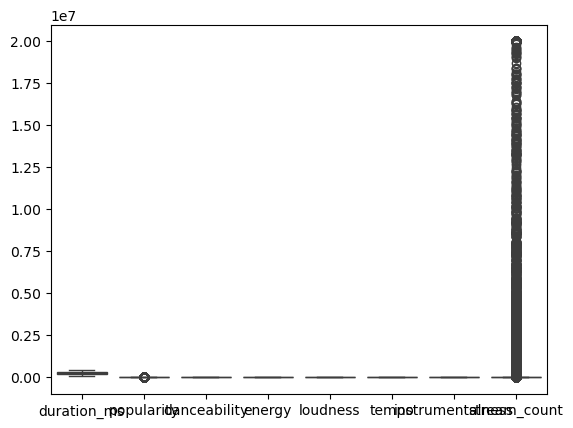

In [17]:
sns.boxplot(new_data[numerical_cols])

<Axes: >

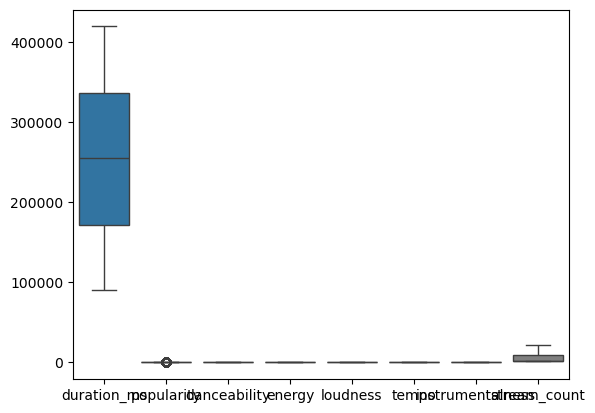

In [18]:
sns.boxplot(data_capped[numerical_cols])

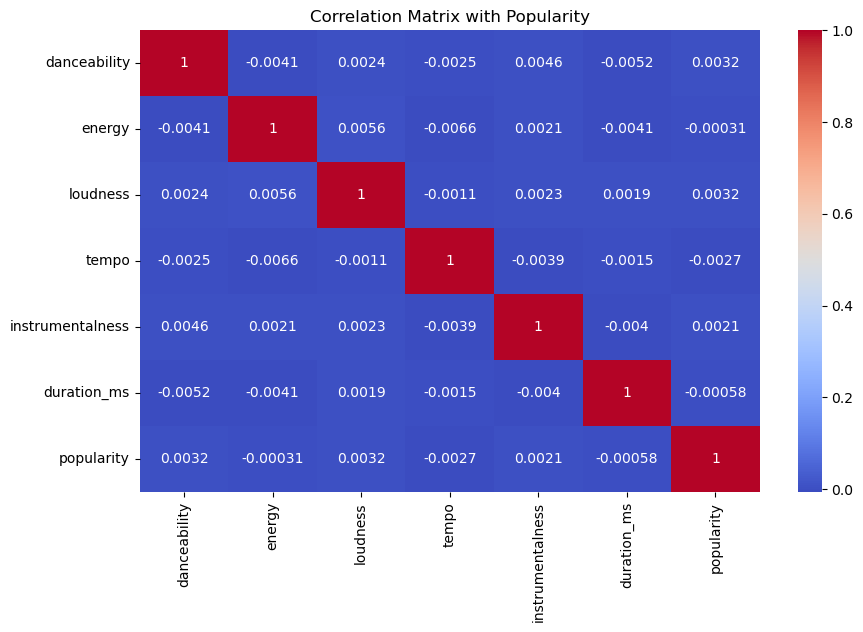

popularity          1.000000
loudness            0.003205
danceability        0.003204
instrumentalness    0.002109
energy             -0.000308
duration_ms        -0.000578
tempo              -0.002727
Name: popularity, dtype: float64

In [20]:

# Select numerical features
num_features = [
    'danceability',
    'energy',
    'loudness',
    'tempo',
    'instrumentalness',
    'duration_ms'
]

# Correlation matrix
corr = data_capped[num_features + ['popularity']].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix with Popularity")
plt.show()

# Correlation with target
corr_with_target = corr['popularity'].sort_values(ascending=False)
corr_with_target


In [22]:
df_model = data_capped.copy()
features_for_pca = [
    'danceability',
    'energy',
    'loudness',
    'tempo',
    'instrumentalness',
    'duration_ms'
]

X = df_model[features_for_pca]


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:", pca.explained_variance_ratio_.sum())


Explained Variance Ratio: [0.16879116 0.16782157]
Total Explained Variance: 0.33661272902803563


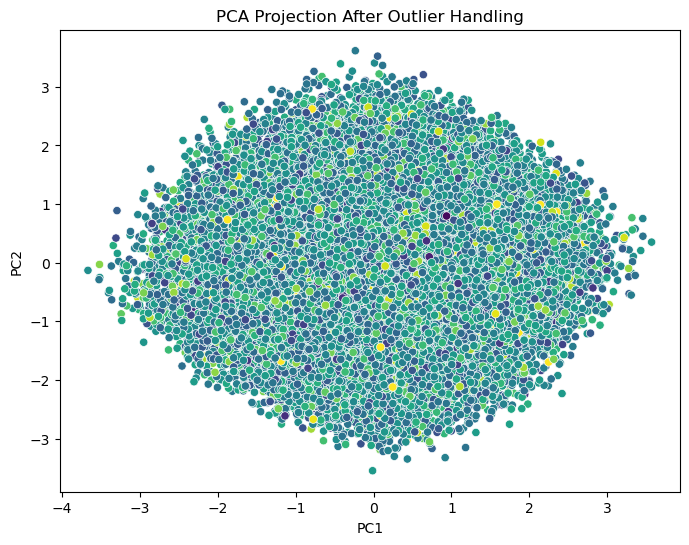

In [26]:
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['popularity'] = df_model['popularity'].values

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='popularity',
    data=pca_df,
    palette='viridis',
    legend=False
)
plt.title("PCA Projection After Outlier Handling")
plt.show()
